Loading

In [25]:

import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import logging
logging.getLogger().setLevel(logging.ERROR) 
basepath = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\branching_ratio\ripple_barr\branching_ratio"
brain_region="CA1"
animal="Rat"   #or Mouse
cell_type='pyr'

basename=os.path.basename(basepath)# Define the new folder path
# Working folder
new_folder_path = os.path.join(basepath, "complex_system")
path_parts = basepath.split("\\")  # Split the path on backslashes
animal_name = path_parts[-2]  # Second-to-last part is the animal name
day = path_parts[-1]  # Last part is the day
# Create the folder if it doesn't exist
if not os.path.exists(new_folder_path):
    os.makedirs(new_folder_path)
    print(f"Folder created: {new_folder_path}")
else:
    print(f"Folder already exists: {new_folder_path}")
# # load in spike data from hpc pyramidal cells
# st, cm = loading.load_spikes(
#     basepath,putativeCellType="Pyr",brainRegion=brain_region #putativeCellType="Pyr|"
# )
# load theta epochs
state_dict = loading.load_SleepState_states(basepath)
nrem_epochs = nel.EpochArray(
    state_dict["NREMstate"],
)
awake_epochs = nel.EpochArray(
    state_dict["WAKEstate"],
)
# theta_epochs = nel.EpochArray(
#     state_dict["THETA"],
# )
rem_epochs=nel.EpochArray(state_dict["REMstate"],)
#spike_times = st.data[(cm.firingRate > 0.2) & (cm.shankID < 5)][:]
# spike_times = st.data[(cm.firingRate > 0.2)][:]

# spike_times.shape

Folder already exists: W:\data\PPP\PPP23\day8\complex_system


Ripples & barrage PSTH

In [26]:
import pickle
def compute_psth_branching_ratio(centers_time, branching_ratios, ripple_start, window=(-50,50), bin_size=2):
    """
    Computes a peri-stimulus time histogram (PSTH) of branching ratios around ripple start times.

    Parameters:
    - centers_time: Array of times (center of each interval) where branching ratios were computed.
    - branching_ratios: Array of branching ratios corresponding to centers_time.
    - ripple_start: Array of ripple start times.
    - window: Time window around each ripple start (start, end) in seconds.
    - bin_size: Size of time bins in seconds.

    Returns:
    - psth_times: Array of times relative to ripple starts.
    - psth_values: Array of mean branching ratios for each time bin.
    """
    # Create relative time bins
    psth_times = np.arange(window[0], window[1] + bin_size, bin_size)
    num_bins = len(psth_times) - 1

    # Initialize matrix to hold branching ratios aligned to ripples
    aligned_ratios = []

    for ripple in ripple_start:
        # Find branching ratios within the window around this ripple
        window_start = ripple + window[0]
        window_end = ripple + window[1]
        
        # Mask to select centers_time within the window
        mask = (centers_time >= window_start) & (centers_time < window_end)
        relative_times = centers_time[mask] - ripple
        relative_ratios = branching_ratios[mask]

        # Bin the branching ratios
        binned_ratios = np.zeros(num_bins)
        for i in range(num_bins):
            bin_mask = (relative_times >= psth_times[i]) & (relative_times < psth_times[i + 1])
            if np.any(bin_mask):
                binned_ratios[i] = np.mean(relative_ratios[bin_mask])
            else:
                binned_ratios[i] = np.nan  # Fill with NaN if no data in bin

        aligned_ratios.append(binned_ratios)

    # Convert to numpy array for aggregation
    aligned_ratios = np.array(aligned_ratios)

    # Compute the PSTH (mean across ripples, ignoring NaNs)
    psth_values = np.nanmean(aligned_ratios, axis=0)
    psth_std = np.nanstd(aligned_ratios, axis=0) / np.sqrt(np.sum(~np.isnan(aligned_ratios), axis=0))
    return psth_times[:-1], psth_values, psth_std,aligned_ratios  # Exclude last bin edge for plotting
def generate_random_points(exclusion_intervals, duration_intervals, ripple_starts):
    """
    Generate random points within duration intervals, excluding specified intervals,
    with the number of random points equal to the count of ripple_start in each interval.
    
    Parameters:
        exclusion_intervals (list of tuples): [(start1, end1), (start2, end2), ...]
        duration_intervals (list of tuples): [(start1, end1), (start2, end2), ...]
        ripple_starts (list): List of ripple start times.
    
    Returns:
        dict: A dictionary mapping each duration interval to its list of random points.
    """
    random_points = []

    # Process each duration fffgg
    for start, end in duration_intervals:
        # Create a mask for this interval
        time_range = np.arange(start, end,step=0.01)
        valid_times = set(time_range,)
        
        # Exclude all exclusion intervals within this duration interval
        for ex_start, ex_end in exclusion_intervals:
            # Restrict to exclusions within the current duration interval
            if ex_start < end and ex_end > start:
                ex_start = max(start, ex_start)
                ex_end = min(end, ex_end)
                valid_times -= set(np.arange(ex_start, ex_end))
        
        valid_times = sorted(valid_times)  # Convert back to sorted list
        
        # Count ripple starts within the current duration interval
        ripple_count = sum((start <= ripple < end) for ripple in ripple_starts)
        
        # Sample random points from valid times
        if len(valid_times) < ripple_count:
            print(f"Skipping interval ({start}, {end}): Not enough valid times to generate {ripple_count} points.")
            continue
        
        sampled_points = np.random.choice(valid_times, size=ripple_count*5, replace=False)
        random_points.extend(sampled_points)  # Append sampled points to the final list
    
    return random_points
import numpy as np

def calculate_br_changes(br_values, time_stamps, ripple_times, center_window, baseline_windows):
    """
    Calculate the branching ratio (BR) dip around ripple events compared to baseline.

    Parameters:
        br_values (np.array): Array of branching ratio values.
        time_stamps (np.array): Array of time stamps corresponding to br_values.
        ripple_times (np.array): Array of ripple event times.
        center_window (tuple): Time window (start, end) for the center dip around ripple.
        baseline_windows (list of tuples): List of time windows [(start1, end1), (start2, end2)] for baseline calculation.

    Returns:
        np.array: Array of BR changes for each ripple event.
    """
    br_changes = []

    for ripple in ripple_times:
        # Get indices for the center window
        center_indices = (time_stamps >= ripple + center_window[0]) & (time_stamps <= ripple + center_window[1])
        
        # Calculate mean BR value in the center window
        center_mean = np.nanmean(br_values[center_indices])
        # Calculate mean BR values for baseline windows
        baseline_means = []
        for baseline_window in baseline_windows:
            baseline_indices = (time_stamps >= ripple + baseline_window[0]) & (time_stamps <= ripple + baseline_window[1])
            baseline_mean = np.nanmean(br_values[baseline_indices])
            baseline_means.append(baseline_mean)
        
        # Calculate overall baseline mean
        baseline_mean = np.nanmean(baseline_means)
        
        # Calculate the change (baseline - center)
        br_change = (center_mean-baseline_mean)/baseline_mean if baseline_mean != 0 else np.nan
        br_changes.append(br_change)
    
    return np.array(br_changes)
def load_results_from_pickle(base_dir, animal_name, day, brain_region, prefix=None):
    """
    Load results from a pickle file with naming convention:
        [{prefix}_]<animal_name>_<day>_<brain_region>.pkl

    Parameters:
    - base_dir: Directory where the pickle file is stored
    - animal_name: Animal identifier (str)
    - day: Day string/number (str or int)
    - brain_region: Brain region (e.g., 'CA1')
    - prefix: Optional prefix used when saving (e.g., 'branching_ratio')

    Returns:
    - data (dict) if file exists
    - None if file does not exist
    """
    # normalize parts
    animal_str = str(animal_name).strip()
    day_str    = str(day).strip()
    region_str = str(brain_region).strip().upper()

    stem = f"branching_ratio_allstates_win10s_step2s_guard5s_{animal_str}_{day_str}_{region_str}"
    #stem = f"{animal_str}_{day_str}_{region_str}"
    if prefix:
        stem = f"{prefix}_{stem}"

    file_path = os.path.join(base_dir, f"{stem}.pkl")

    if os.path.exists(file_path):
        with open(file_path, "rb") as f:
            data = pickle.load(f)
        print(f"✅ Loaded: {file_path}")
        return data
    else:
        print(f"⚠️ File not found: {file_path}")
        return None

In [27]:

from nelpy.core import EpochArray
import scipy

import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import logging
import scipy.io as sio
#create working folder
ripple_events=loading.load_ripples_events(basepath=basepath)
ripple_epochs = EpochArray(np.array([ripple_events.peaks, ripple_events.peaks]).T)
ripples_in_nrem = ripple_epochs & nrem_epochs
#ripples_in_nrem = ripple_epochs & nrem_intervals
ripple_start=ripples_in_nrem.data[:,0]

# Combine ripple and barrage intervals into exclusion windows
barrage_start=[]
exclusion_intervals = np.array(
    [(start-1, stop+1) for start, stop in zip(ripple_events.start, ripple_events.stop)] +
    [(start-1, start+1) for start in barrage_start]
)
ripple_random_times = generate_random_points(exclusion_intervals, nrem_epochs.data, ripple_start)



✅ Loaded: D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\branching_ratio\ripple\branching_ratio_allstates_win10s_step2s_guard5s_PPP23_day8_CA1.pkl
dict_keys(['meta', 'NREM', 'REM', 'THETA', 'nonTHETA'])


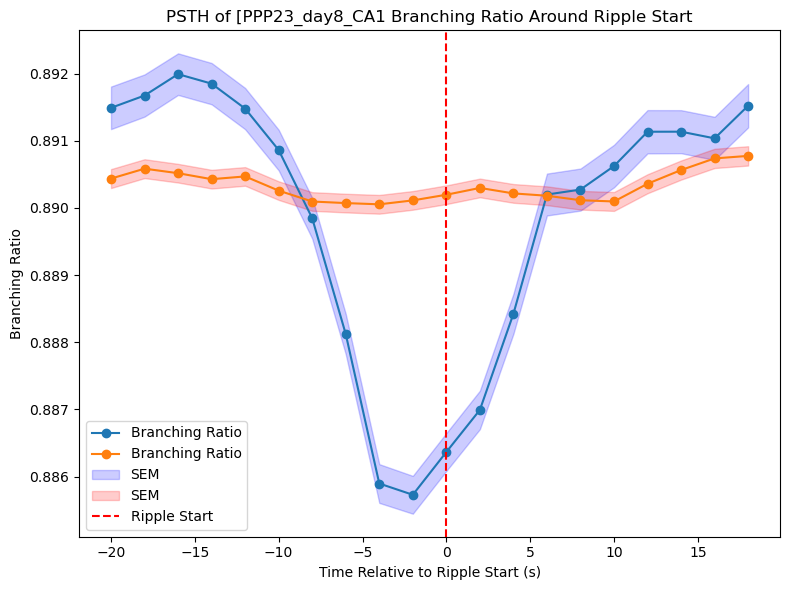

C:\Users\Cornell\AppData\Local\Temp\ipykernel_72872\3019250354.py:118: RuntimeWarning: Mean of empty slice
C:\Users\Cornell\AppData\Local\Temp\ipykernel_72872\3019250354.py:123: RuntimeWarning: Mean of empty slice
C:\Users\Cornell\AppData\Local\Temp\ipykernel_72872\3019250354.py:127: RuntimeWarning: Mean of empty slice


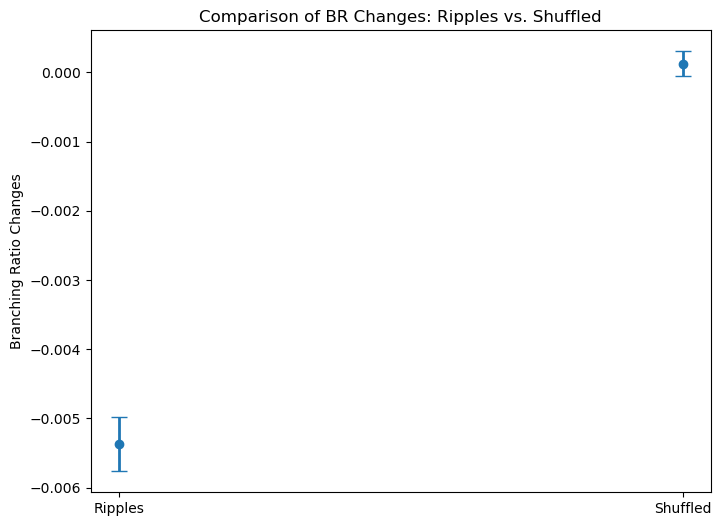

✅ Saved branching ratio result to: D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\branching_ratio\ripple\changes\PPP23_day8_CA1_br_changes_.pkl


'D:\\Documents\\GitHub\\Sleep_criticaltiy\\data\\ripple_barr\\branching_ratio\\ripple\\changes\\PPP23_day8_CA1_br_changes_.pkl'

In [28]:
# Example Usage
import scipy.io
results={}
base_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\branching_ratio\ripple"

# Branching-ratio windows of this session
data = load_results_from_pickle(base_dir, animal_name, day, brain_region, prefix=None)

# Files saved with prefix="branching_ratio":
# data = load_results_from_pickle(base_dir, "PPP7", "day7", "CA1", prefix="branching_ratio")
#results_load=data['results']
results_load=data['NREM']
print(data.keys())  # keys: "results" and "meta"
# results_load=data['NREM']
centers_time = results_load['centers'] # Example centers (in seconds)
branching_ratios = results_load["branching_ratios"]  # Example branching ratios
centers_time = np.array(centers_time)
branching_ratios = np.array(branching_ratios)
# Compute PSTH
psth_times1, psth_values1, psth_sem1,aligned_ratios = compute_psth_branching_ratio(centers_time, branching_ratios, ripple_start,window=(-20,20), bin_size=2)
psth_times2, psth_values2, psth_sem2,aligned_ratios_shuffle = compute_psth_branching_ratio(centers_time, branching_ratios, ripple_random_times,window=(-20,20), bin_size=2)
file_name = f"ripple_PSTH_branchingratio_[{animal_name}_{day}_{brain_region}].png"
# Create the folder if needed
new_folder_path=os.path.join(base_dir, "individual_fig")
# Full path for saving the figure
save_path = os.path.join(new_folder_path, file_name)
# Plot the PSTH with shadow
plt.figure(figsize=(8, 6))
plt.plot(psth_times1, psth_values1, marker='o', label="Branching Ratio")
plt.plot(psth_times2, psth_values2, marker='o', label="Branching Ratio")
plt.fill_between(psth_times1, psth_values1 - psth_sem1, psth_values1 + psth_sem1, alpha=0.2, color='blue', label="SEM")
plt.fill_between(psth_times2, psth_values2 - psth_sem2, psth_values2 + psth_sem2, alpha=0.2, color='red', label="SEM")
plt.axvline(0, color='red', linestyle='--', label="Ripple Start")
plt.xlabel("Time Relative to Ripple Start (s)") 
plt.ylabel("Branching Ratio")
plt.title(f"PSTH of [{animal_name}_{day}_{brain_region} Branching Ratio Around Ripple Start")
plt.legend()
plt.tight_layout()
plt.savefig(save_path, dpi=300)
plt.grid(False)
plt.show()

# Define time windows
center_window = (-2.5, 2.5)  # Window for dip around ripple
baseline_windows = [(-20, -20+2.5), (20-2.5, 20)]  # Windows for baseline calculation
br_result={}
# Calculate BR changes
br_changes = calculate_br_changes( branching_ratios, centers_time,ripple_start, center_window, baseline_windows)
br_changes_shuffle = calculate_br_changes(branching_ratios,centers_time, ripple_random_times, center_window, baseline_windows)
br_result['ripples_br_changes']=br_changes
br_result['ripples_br_changes_shuffle']=br_changes_shuffle

data = [br_changes, br_changes_shuffle]
labels = ['Ripples', 'Shuffled']

    # Create the box plot
import numpy as np
import matplotlib.pyplot as plt

# --- compute mean and SEM ---
means = [np.nanmean(d) for d in data]
sems  = [np.nanstd(d, ddof=1) / np.sqrt(np.sum(np.isfinite(d))) for d in data]

# --- plot ---
plt.figure(figsize=(8, 6))

x = np.arange(len(data))
plt.errorbar(
    x, means, yerr=sems,
    fmt='o', capsize=6, linewidth=2
)


plt.xticks(ticks=x, labels=labels)
plt.ylabel("Branching Ratio Changes")
plt.title("Comparison of BR Changes: Ripples vs. Shuffled")
plt.grid(False)

# --- save ---
file_name = f"ripple_PSTH_br_changes_[{animal_name}_{day}_{brain_region}].png"
save_path = os.path.join(new_folder_path, file_name)
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

import pickle

def save_br_result(base_dir, animal_name, day, brain_region, br_result):
    """
    Save branching ratio results to a pickle file.

    File path:
        {base_dir}/{animal_name}_{day}_{brain_region}_br_changes.pkl
    """
    os.makedirs(base_dir, exist_ok=True)

    file_name = f"{animal_name}_{day}_{brain_region}_br_changes_.pkl"
    file_path = os.path.join(base_dir, file_name)

    with open(file_path, "wb") as f:
        pickle.dump(br_result, f)

    print(f"✅ Saved branching ratio result to: {file_path}")
    return file_path
base_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\branching_ratio\ripple\changes"
save_br_result(base_dir, animal_name, day, brain_region, br_result)



In [29]:
#example PPP21 day5